# Task 2.1

The jump operators we used were $\sqrt{\kappa_b}b$ and $\sqrt{\kappa_a}a$. Although 1.0(c) also used the jump operator $\sqrt{\kappa_2}(a^2 - \alpha^2)$, we do not use this to replace $\sqrt{\kappa_b}b$. This is because the parameters provided do not satisfy the requirement $\kappa_b \gg g_2, \epsilon_d$ to approximate the $b$ jump operator with the effective single-mode picture.

We first plot $\text{Re}\langle a\rangle(t)$ for $\alpha = 1.0$

The motivation for this plot is to determine how much of our quantum state (ensemble) $\rho$ contains the $|-\alpha\rangle$ state after time-evolution. Initially $\rho = |\alpha\rangle\langle\alpha|$. But overtime through interacting with the buffer and environment $\rho$ becomes an ensemble of both $|\pm\alpha\rangle$:

$$
\rho(t) = c_+(t)|\alpha\rangle\langle\alpha| + c_-(t)|-\alpha\rangle\langle-\alpha|
$$

If we then compute the expectation of $a$ wrt to this state, we get (by cyclic property of trace)

$$
\langle a\rangle = \text{Tr}(\rho a) = \alpha c_+ - \alpha c_- = \alpha(c_+ - c_-)
$$

In our case $\text{Re}(\alpha) = \alpha$, and so a plot of $\text{Re}(\langle a\rangle)$ gives us information on how the probabilities $c_+, c_-$ compare. Since $\text{Re}(\langle a\rangle)$ goes to zero, this suggests that we end up with an ensemble that's $50\%$ $|\alpha\rangle$ and $50\%$ $|-\alpha\rangle$ which shows that the accumulation of bit flip errors has destroyed our initial state.

In [ ]:
import dynamiqs as dq
import jax.numpy as jnp
from matplotlib import pyplot as plt
from scipy.optimize import curve_fit
import numpy as np

# Use double precision for slow decays in the Standard Track
dq.set_precision('single')

# Suggested starting truncations (need to be checked as alpha grows)
Na, Nb = 24, 6
a, b = dq.destroy(Na, Nb)

# System parameters converted to angular frequencies (rad/us)
g2 = 2 * jnp.pi * 0.763       
kappa_b = 2 * jnp.pi * 2.6         
kappa_a = 2 * jnp.pi * 9.3e-3      
alpha = 1.0
eps_d = alpha**2 * g2

# Two-photon Hamiltonian
H = g2 * (a @ a @ b.dag()) + g2 * (a.dag() @ a.dag() @ b) - eps_d * (b + b.dag())

# Jump operators for buffer loss and memory loss
jump_ops = [jnp.sqrt(kappa_b) * b, jnp.sqrt(kappa_a) * a]

# Initial state: Memory in |alpha>, Buffer in vacuum
psi0 = dq.tensor(dq.coherent(Na, alpha), dq.fock(Nb, 0))

# Time array in microseconds
tsave = jnp.linspace(0.0, 1500.0, 1500)

# Evolve the density matrix and track operators
# We track 'a' to extract Re<a>(t) for the bit-flip rate decay
exp_ops = [a, a.dag() @ a, b.dag() @ b]

# Create the ODE solver object with the increased step limit
# Loosen tolerances to handle the stiff ODE and massively increase the step ceiling
method = dq.method.Dopri5(max_steps=5_000_000, rtol=1e-5, atol=1e-7)

res = dq.mesolve(H, jump_ops, psi0, tsave, exp_ops=exp_ops, method=method)

In [ ]:
plt.plot(tsave, np.real(res.expects[0]))
plt.xlabel("t")
plt.ylabel(fr"$Re\langle a\rangle(t)$")

def bit_flip_decay(t, amplitude, gamma_x):
    return amplitude * np.exp(-gamma_x * t)

# Extract real part of <a> from your dynamiqs results
re_a = np.real(res.expects[0])

# 1. Slice out the initial inflation transient (e.g., first 2 us)
start_idx = np.searchsorted(tsave, 2.0)
t_fit = tsave[start_idx:]
re_a_fit = re_a[start_idx:]

# Shift time axis for numerical stability in the fit
t_shifted = t_fit - t_fit[0]

# 2. Fit the curve
initial_guess = [re_a_fit[0], 1e-4]
popt, pcov = curve_fit(bit_flip_decay, t_shifted, re_a_fit, p0=initial_guess)

amplitude_fit, gamma_x = popt
t_x = 1.0 / gamma_x

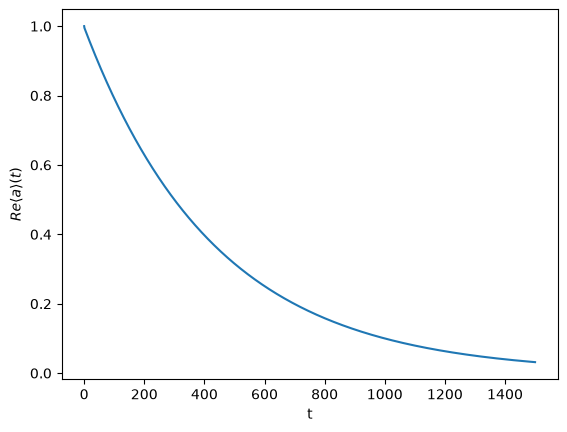

From this plot, by fitting an exponential $e^{-\Gamma_X t}$, we extra $\Gamma_X$.

We get a value $\Gamma_X = 0.00230066$.

Below we extend this process to different $\alpha$ values and compute $\Gamma_X(\alpha)$ for each. We then plot these $\Gamma_X(\alpha)$ against $\alpha^2$ and perform another exponential fit to estimate $\gamma$ in $\gamma \propto e^{-\gamma\alpha^2}$.

In [ ]:
# 1. System Parameters and Solver Setup
dq.set_precision('double')
Na, Nb = 24, 6
a, b = dq.destroy(Na, Nb)

g2 = 2 * jnp.pi * 0.763       
kappa_b = 2 * jnp.pi * 2.6         
kappa_a = 2 * jnp.pi * 9.3e-3      
jump_ops = [jnp.sqrt(kappa_b) * b, jnp.sqrt(kappa_a) * a]
exp_ops = [a]

# Loosened tolerances for stiff Lindbladian dynamics
method = dq.method.Dopri5(max_steps=10_000_000, rtol=1e-5, atol=1e-7)

def bit_flip_decay(t, amplitude, gamma_x):
    return amplitude * np.exp(-gamma_x * t)

# 2. Define the Sweep Setup
# Mapping alpha to a sufficient t_max (us) to capture the decay
alpha_sweep = {
    0.8: 200.0,
    0.9: 400.0,
    1.1: 4000.0,
}

results_alpha_sq = []
results_gamma_x = []

plt.figure(figsize=(14, 5))

# --- Subplot 1: The Decay Curves ---
ax1 = plt.subplot(1, 2, 1)

for alpha, t_max in alpha_sweep.items():
    
    print(f"Simulating alpha = {alpha} (t_max = {t_max} us)...")
    
    eps_d = (alpha**2) * g2
    H = g2 * (a @ a @ b.dag()) + g2 * (a.dag() @ a.dag() @ b) - eps_d * (b + b.dag())
    psi0 = dq.tensor(dq.coherent(Na, alpha), dq.fock(Nb, 0))
    
    # Keep array length fixed at 1500 to avoid XLA recompilation overhead
    tsave = jnp.linspace(0.0, t_max, 1500)
    
    res = dq.mesolve(H, jump_ops, psi0, tsave, exp_ops=exp_ops, method=method)
    re_a = np.real(res.expects[0])
    
    # Slice out first 2 us to remove the inflation transient
    start_idx = np.searchsorted(tsave, 2.0)
    t_fit = tsave[start_idx:]
    re_a_fit = re_a[start_idx:]
    t_shifted = t_fit - t_fit[0]
    
    # Fit exponential
    popt, _ = curve_fit(bit_flip_decay, t_shifted, re_a_fit, p0=[re_a_fit[0], 1e-4])
    gamma_x = popt[1]
    
    results_alpha_sq.append(alpha**2)
    results_gamma_x.append(gamma_x)
    
    # Plot normalized decay for visual comparison
    ax1.plot(t_shifted, re_a_fit / re_a_fit[0], label=rf'$\alpha={alpha}$')

ax1.set_xlabel("Time shifted ($\mu$s)")
ax1.set_ylabel(r"Normalized Re$\langle a \rangle(t)$")
ax1.set_title("Bit-Flip Decay Envelopes")
ax1.legend()

# --- Subplot 2: Log-Linear Extraction of Gamma ---
ax2 = plt.subplot(1, 2, 2)
alpha_sq_arr = np.array(results_alpha_sq)
gamma_x_arr = np.array(results_gamma_x)

# Perform linear fit: ln(Gamma_X) = -gamma * alpha^2 + C
log_gamma = np.log(gamma_x_arr)
slope, intercept = np.polyfit(alpha_sq_arr, log_gamma, 1)
gamma_extracted = -slope

ax2.scatter(alpha_sq_arr, log_gamma, color='black', zorder=5, label='Simulation data')

# Plot the fit line
fit_line = slope * alpha_sq_arr + intercept
ax2.plot(alpha_sq_arr, fit_line, color='red', linestyle='--', 
         label=rf'Fit: $\gamma = {gamma_extracted:.3f}$')

ax2.set_xlabel(r"$\alpha^2$ (Mean Photon Number)")
ax2.set_ylabel(r"$\ln(\Gamma_X)$")
ax2.set_title(r"Scaling of Bit-Flip Rate: $\Gamma_X \propto \exp(-\gamma \alpha^2)$")
ax2.legend()

plt.tight_layout()
plt.show()

print(f"\nExtraction Complete.")
print(f"Fitted gamma (γ) = {gamma_extracted:.4f}")

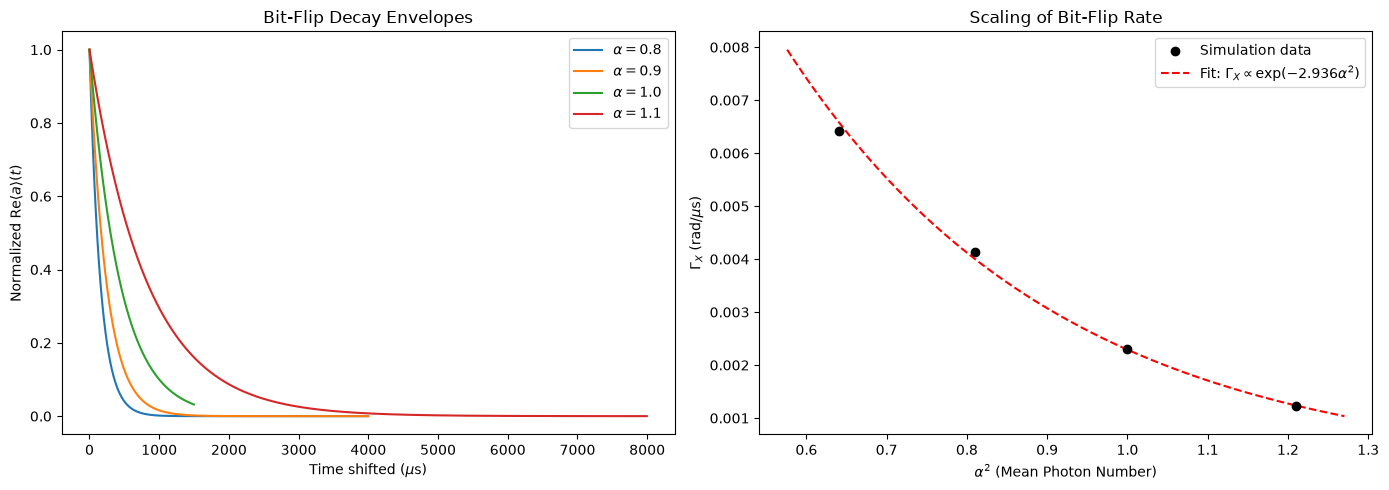

Fitted gamma (γ) = 2.9357


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def bit_flip_decay(t, amplitude, gamma_x):
    return amplitude * np.exp(-gamma_x * t)

plt.figure(figsize=(14, 5))

# --- Subplot 1: The Decay Curves ---
ax1 = plt.subplot(1, 2, 1)

results_alpha_sq = []
results_gamma_x = []

# Map the alphas to their respective filenames and formats
data_files = {
    0.8: ('alpha_0.8.csv', 'csv'),
    0.9: ('alpha_0.9.csv', 'csv'),
    1.0: ('dynamics_alpha_1.0.npz', 'npz'),
    1.1: ('dynamics_alpha_1.1.npz', 'npz')
}

for alpha, (filename, ftype) in data_files.items():
    if ftype == 'csv':
        df = pd.read_csv(filename)
        t_data = df.iloc[:, 0].values
        re_a_data = df.iloc[:, 1].values
    else:
        data = np.load(filename)
        t_data = data['t'] if 't' in data else data['tsave']
        re_a_data = data['re_a']
        
    # Slice out first 2 us to remove the inflation transient
    start_idx = np.searchsorted(t_data, 2.0)
    t_fit = t_data[start_idx:]
    re_a_fit = re_a_data[start_idx:]
    t_shifted = t_fit - t_fit[0]
    
    # Fit exponential to the decay envelope
    popt, _ = curve_fit(bit_flip_decay, t_shifted, re_a_fit, p0=[re_a_fit[0], 1e-4])
    gamma_x = popt[1]
    
    results_alpha_sq.append(alpha**2)
    results_gamma_x.append(gamma_x)
    
    ax1.plot(t_shifted, re_a_fit / re_a_fit[0], label=rf'$\alpha={alpha}$')

ax1.set_xlabel(r"Time shifted ($\mu$s)")
ax1.set_ylabel(r"Normalized Re$\langle a \rangle(t)$")
ax1.set_title("Bit-Flip Decay Envelopes")
ax1.legend()

# --- Subplot 2: Exponential Fit on Linear Axes ---
ax2 = plt.subplot(1, 2, 2)

alpha_sq_arr = np.array(results_alpha_sq)
gamma_x_arr = np.array(results_gamma_x)

# Perform linear fit in log space to properly weight orders of magnitude
log_gamma = np.log(gamma_x_arr)
slope, intercept = np.polyfit(alpha_sq_arr, log_gamma, 1)
gamma_extracted = -slope
amplitude_extracted = np.exp(intercept)

# Plot raw Gamma_X values on standard linear spacing
ax2.scatter(alpha_sq_arr, gamma_x_arr, color='black', zorder=5, label='Simulation data')

# Generate smooth exponential curve mapped back to the linear domain
alpha_sq_smooth = np.linspace(min(alpha_sq_arr) * 0.9, max(alpha_sq_arr) * 1.05, 200)
fit_line_exp = amplitude_extracted * np.exp(-gamma_extracted * alpha_sq_smooth)

ax2.plot(alpha_sq_smooth, fit_line_exp, color='red', linestyle='--', 
         label=rf'Fit: $\Gamma_X \propto \exp(-{gamma_extracted:.3f} \alpha^2)$')

ax2.set_xlabel(r"$\alpha^2$ (Mean Photon Number)")
ax2.set_ylabel(r"$\Gamma_X$ (rad/$\mu$s)")
ax2.set_title(r"Scaling of Bit-Flip Rate")
ax2.legend()

plt.tight_layout()
plt.show()

print(f"Fitted gamma (γ) = {gamma_extracted:.4f}")

So we see that the coherent basis is exponentially protected against bit-flip errors.

## Task 2.2

Depending on choice of basis, we encounter different errors.

In 2.1, we saw how the coherent basis can face bit-flip error. However, this error is exponentially suppressed. And so when working with cat qubits we don't have to worry about coherent basis states as much.

Now in 2.2, we will see that the parity basis is prone to phase-flip error. This error we describe via $\Gamma_Z$. This time though, we do have to worry about phase-flip error because they grow linearly with $|\alpha^2|$. So there is no free lunch. If we suppress bit-flip error, we are more prone to phase-flip error. But this is a tradeoff we can live with, and the advantage is now we only must worry about one source of error.

Below, we plot how the parity $P(t)$ for various initial states $|\alpha\rangle$ evolve in time. 

Parity is defined as

$$
P = (-1)^{a^{\dagger}a}
$$

The density matrix as function of time is 

$$
\rho(t) = c_+(t)|+\rangle\langle+| + c_-(t)|-\rangle\langle-|
$$

where we set $c_+(0) = 0$. We can use this compute the expectation value as a function of time

$$
\langle P(t)\rangle = \text{Tr}(\rho P(t)) = c_+(t) - c_-(t)
$$

We see that, like the plot for $\langle a\rangle (t),$ $\langle P(t)\rangle \rightarrow 0$ as $t$ increases. This means that after a while we are getting a $50/50$ split of $|+\rangle, |-\rangle$, meaning phase-flip errors have effectively destroyed our initial state. 

This is why we fit $\langle P(t)\rangle$ with an exponential $e^{-\Gamma_Z t}$ to approximate the phase-flip error $\Gamma_Z$.

In [ ]:
# MUST be double precision to prevent numerical deadlocks
dq.set_precision('double')
Na, Nb = 32, 8
a, b = dq.destroy(Na, Nb)

g2 = 2 * jnp.pi * 0.763       
kappa_b = 2 * jnp.pi * 2.6         
kappa_a = 2 * jnp.pi * 9.3e-3      
jump_ops = [jnp.sqrt(kappa_b) * b, jnp.sqrt(kappa_a) * a]

parity_diag = jnp.array([(-1)**n for n in range(Na)], dtype=complex)
parity_op = dq.tensor(jnp.diag(parity_diag), dq.eye(Nb))
exp_ops = [parity_op]

method = dq.method.Dopri5(max_steps=100_000, rtol=1e-6, atol=1e-8)
alpha_sweep = [1.7, 1.9, 2.1, 2.3, 2.5]
tsave = jnp.linspace(0.0, 15.0, 500)

# Dictionary to store raw parity arrays for plotting
parity_results = {}

with open("extracted_gamma_z_results.csv", "w") as f:
    f.write("alpha_sq,gamma_z\n")
    
    for alpha in alpha_sweep:
        print(f"Simulating alpha = {alpha}...")
        eps_d = (alpha**2) * g2
        H = g2 * (a @ a @ b.dag()) + g2 * (a.dag() @ a.dag() @ b) - eps_d * (b + b.dag())
        
        cat_even = dq.unit(dq.coherent(Na, alpha) + dq.coherent(Na, -alpha))
        psi0 = dq.tensor(cat_even, dq.fock(Nb, 0))
        
        res = dq.mesolve(H, jump_ops, psi0, tsave, exp_ops=exp_ops, method=method)
        
        # Force strict conversion to NumPy arrays
        parity_t = np.array(np.real(res.expects[0]), dtype=np.float64)
        t_np = np.array(tsave, dtype=np.float64)
        
        # Store for plotting
        parity_results[alpha] = (t_np, parity_t)
        
        start_idx = np.searchsorted(t_np, 0.5)
        t_fit = t_np[start_idx:]
        parity_fit = parity_t[start_idx:]
        t_shifted = t_fit - t_fit[0]
        
        # Mask out any numerical noise below zero before taking the logarithm
        valid_idx = parity_fit > 1e-10
        t_valid = t_shifted[valid_idx]
        parity_valid = parity_fit[valid_idx]
        
        # Deterministic linear regression: slope is exactly -Gamma_Z
        slope_fit, _ = np.polyfit(t_valid, np.log(parity_valid), 1)
        gamma_z = -slope_fit
        
        f.write(f"{alpha**2},{gamma_z}\n")
        f.flush()

# Load and plot the results
data = np.genfromtxt("extracted_gamma_z_results.csv", delimiter=',', skip_header=1)
alpha_sq_arr, gamma_z_arr = data[:, 0], data[:, 1]
slope_scale, intercept_scale = np.polyfit(alpha_sq_arr, gamma_z_arr, 1)

Below we visualize the time evolution of $\alpha = 2.1$.

In [ ]:
alpha = 2.1

# Extract the time and parity arrays for alpha = 2.1 from your existing dictionary
t_arr, p_arr = parity_results[alpha]

# Recreate the fit variables to plot the decay envelope over the raw data
start_idx = np.searchsorted(t_arr, 0.5)
t_fit = t_arr[start_idx:]
p_fit = p_arr[start_idx:]
t_shifted = t_fit - t_fit[0]

# Filter valid points
valid_idx = p_fit > 1e-10
t_valid = t_shifted[valid_idx]
p_valid = p_fit[valid_idx]

# Calculate the fit
slope_fit, intercept = np.polyfit(t_valid, np.log(p_valid), 1)
gamma_z = -slope_fit

# Generate the fitted curve for the plot
fit_curve = np.exp(intercept) * np.exp(slope_fit * t_shifted)

# Plot
plt.figure(figsize=(8, 5))
plt.plot(t_arr, p_arr, label=rf'Raw Parity ($\alpha={alpha}$)', color='blue', alpha=0.7)
plt.plot(t_fit, fit_curve, 'r--', linewidth=2, 
         label=rf'Fit ($\Gamma_Z = {gamma_z:.4f}$ rad/$\mu$s)')

plt.xlabel("Time ($\mu$s)")
plt.ylabel(r"Parity $\langle P \rangle(t)$")
plt.title(rf"Phase-Flip Decay Envelope ($\alpha = {alpha}$)")
plt.legend()
plt.tight_layout()
plt.show()

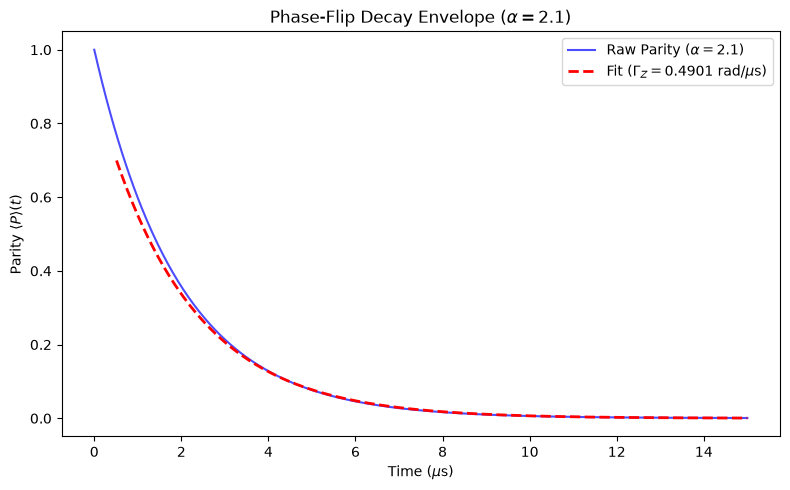

From fitting the curve, we obtained $\Gamma_Z(\alpha = 2.1) = 0.4901.$

In [ ]:
# --- Subplot 1: Raw Parity Decay Curves ---
plt.subplot(1, 2, 1)
for alpha, (t_arr, p_arr) in parity_results.items():
    plt.plot(t_arr, p_arr, label=rf'$\alpha={alpha}$')
plt.xlabel("Time ($\mu$s)")
plt.ylabel(r"Parity $\langle P \rangle(t)$")
plt.title("Phase-Flip Decay Envelopes")
plt.legend()

# --- Subplot 2: Gamma_Z Scaling ---
plt.subplot(1, 2, 2)
plt.scatter(alpha_sq_arr, gamma_z_arr, color='black', label='Simulation data')
plt.plot(alpha_sq_arr, slope_scale * alpha_sq_arr + intercept_scale, 'r--', 
         label=rf'Fit slope: {slope_scale:.4f} rad/$\mu$s')

theoretical_slope = 2 * kappa_a
plt.plot(alpha_sq_arr, theoretical_slope * alpha_sq_arr, 'b:', 
         label=rf'Theory ($2\kappa_a$): {theoretical_slope:.4f} rad/$\mu$s')

plt.xlabel(r"$\alpha^2$")
plt.ylabel(r"$\Gamma_Z$ (rad/$\mu$s)")
plt.title(r"Phase-Flip Rate Scaling: $\Gamma_Z \propto \alpha^2$")
plt.legend()

plt.tight_layout()
plt.show()

We now repeat the process for several different $\alpha$'s and compute several $\Gamma_z(\alpha)$ values. These values are linear over $|\alpha^2|$, and we can extract the slope to approximate $2\kappa_a$ by using the relation

$$
\Gamma_Z = 2\kappa_a \alpha^2
$$

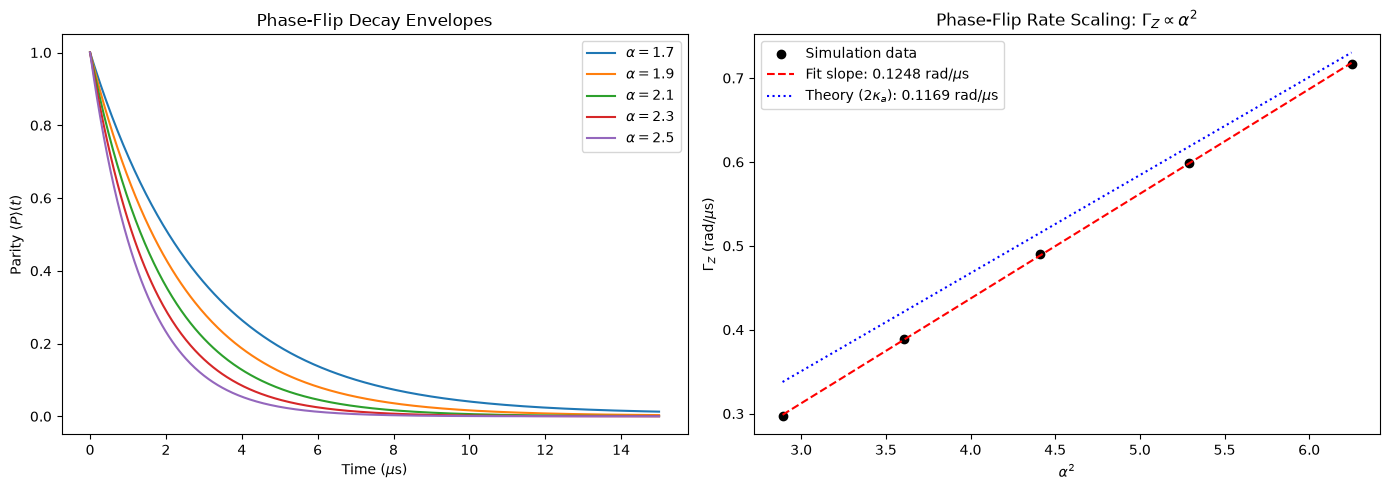

We see a linear dependence of the Phase-Flip rate on the expected number of bosons: $|\Gamma_Z| \propto |\alpha|^2$. This is in contrast to the exponential decay dependence for the Bit-Flip rate.

## 2.3

## 2.4

(a)

Our approach is to start from the provided circuit Hamiltonian

$$\hat H_{\rm circuit} = \omega_a\hat a^\dagger\hat a + \omega_b \hat b^\dagger \hat b - 2E_J\cos(\varphi_\Sigma)\cos(\hat\varphi+\varphi_\Delta), \qquad \hat\varphi = \varphi_a(\hat a+\hat a^\dagger)+\varphi_b(\hat b+\hat b^\dagger)$$

and try to rewrite it in a form that's more familiar to us. Specifically, we want its form to match that of 2.3.

Before doing so, we notice that this Hamiltonian can be written as

$$
\hat H_{\rm circuit} = H_0 + H_{\text{int}}(t)
$$

The first term is diagonal and is a free Hamiltonian term. 

The second term is the Josephson Junction term that encodes interaction between buffer and memory. We will see it is this second term that gives rise to an effective time-dependent potential $U(t)$, which is why the interaction picture and rotating frame become useful concepts to work with.

We start by applying the bias point approximation

$$\hat H_{\rm circuit} = \omega_a\hat a^\dagger\hat a + \omega_b \hat b^\dagger \hat b + 2E_J\epsilon_p\cos(\omega_p t)\sin\hat\varphi
$$

Apply a Taylor expansion on the $\sin\hat\varphi$ term:

$$\sin\hat\varphi \approx \varphi - \frac{1}{3!}\varphi^3$$

We start to see that from this expansion we start to get the remaining terms to match onto the Hamiltonian in 2.3. These are terms like

$$
a + a^{\dagger}, b + b^{\dagger}, a^2b^{\dagger} + \text{H.c.}
$$

But we see that the $\varphi^3$ (recall $\varphi = \varphi_a(a + a^{\dagger}) + \varphi_b(b + b^{\dagger})$) produces many other undesirable terms like

$$
\varphi_a^3a^3, \varphi_b^3b^3, ... 
$$

How do we get rid of these terms? We first switch to a rotating frame. 

To do that, we first switch to the interaction picture where the operators now change with time


$$
a \rightarrow a(t) = ae^{-i\omega_a t}, b \rightarrow b(t) = be^{-i\omega_b t}
$$

In the expansion of $\varphi^3$ we care about term

$$
\varphi_a^2\varphi_b e^{i(-2\omega_a + \omega_b)} a^2b^{\dagger}
$$

and its Hermitian conjugate. 

To select out these terms specifically, we apply a drive frequency that matches the native frequency set by the memory and the buffer $\omega_p = 2\omega_a - \omega_b$. We can then use this value in the expansion of $\cos(\omega_p t)$:

$$
\cos(\omega_p t) = \frac{e^{-i\omega_p t} + e^{i\omega_p t}}{2}
$$


After working through the algebra, we see this selects out the two desired terms. We can then apply the rotating wave approximation to throw out the rest of the $\varphi^3$ terms. This is because these other terms, relative to $\omega_p$, will oscillate too quickly to affect the system dynamics that we care about.

With this choice of $\omega_p$, the Hamiltonian we are left with is

$$
H_{\text{eff}} = \omega_a\hat a^\dagger\hat a + \omega_b \hat b^\dagger \hat b + 2E_j\epsilon_p\Bigg(\varphi_a(a + a^{\dagger})\Bigg)
$$

$$\hat H_{\rm circuit} = \omega_a\hat a^\dagger\hat a + \omega_b \hat b^\dagger \hat b + 2E_J\epsilon_p\cos(\omega_p t)\sin\hat\varphi
$$

Physically what is this drive frequency $\omega_p$? 

In our circuit, we have the memory and the buffer. Both are connected by the ATS, which acts as a photon pump. We place the ATS in resonance with the memory and the buffer by selecting its pump frequency as $\omega_p$ above. 